# Supervised Learning

**Question:** Do traditional NBA statistics add predictive value beyond Kalshi prediction-market prices, and does that change as a game progresses?

Compares three feature sets (NBA stats only, Kalshi price only, and both combined) across three model types at four checkpoints: pre-game and the end of quarters 1–3. Every model is evaluated two ways: with 5-fold time-series cross-validation on the training games, and once on the same held-out test games. Both are compared against the raw Kalshi market price.

All data loading, checks, feature engineering, and the train/test split happen in `03_data_prep.ipynb`. This notebook reads its output from `data/processed/`.

## 1. Setup

Imports libraries and defines the constants used throughout the notebook: the processed-data folder, the four checkpoints (matching the processed file names), and the random seed for reproducible models and bootstrap samples.

In [2]:
%pip install -q -r ../requirements.txt

You should consider upgrading via the '/Users/ryanmccurry/Desktop/Projects/Milestone2/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

PROCESSED_DIR = Path("../data/processed")
CHECKPOINTS = ["pregame", "endq1", "endq2", "endq3"]
LABELS = ["Pre-game", "End Q1", "End Q2", "End Q3"]
RANDOM_STATE = 42

VIZ_DIR = Path("../visualizations")
VIZ_DIR.mkdir(exist_ok=True)

## 2. Load Data

Loads one table per checkpoint from `03_data_prep.ipynb`. Each has the same 1,141 games, one row per game, with the target `HOME_WIN`, home-minus-away features (`ROLL_*` rolling stats, `IG_*` in-game stats for end-of-quarter checkpoints, and `KALSHI_PROB_HOME`), and a `SPLIT` column marking the chronological train/test split (train before Mar 7, 2026).

In [2]:
tables = {
    checkpoint: pd.read_csv(PROCESSED_DIR / f"{checkpoint}.csv", parse_dates=["GAME_DATE"])
    for checkpoint in CHECKPOINTS
}

Preview of an end-of-quarter table:

In [3]:
tables["endq1"].head()

,GAME_ID,GAME_DATE,HOME_WIN,KALSHI_PROB_HOME,ROLL_FGM,ROLL_FGA,ROLL_FG_PCT,ROLL_FG3M,ROLL_FG3A,ROLL_FG3_PCT,ROLL_FTM,ROLL_FTA,ROLL_FT_PCT,ROLL_OREB,ROLL_DREB,ROLL_REB,ROLL_AST,ROLL_STL,ROLL_BLK,ROLL_TOV,ROLL_PF,ROLL_PTS,ROLL_PLUS_MINUS,IG_FGM,IG_FGA,IG_FG_PCT,IG_FG3M,IG_FG3A,IG_FG3_PCT,IG_FTM,IG_FTA,IG_FT_PCT,IG_OREB,IG_DREB,IG_REB,IG_AST,IG_STL,IG_BLK,IG_TOV,IG_PF,IG_SCORE_DIFF,SPLIT
0,22500022,2025-10-31,0,0.480000,-5.6,-3.4,-0.05,2.8,11.6,-0.04,3.2,4.0,0.01,1.0,3.4,4.4,-5.2,0.8,0.8,1.4,-3.2,-5.2,7.4,-7,5,-0.461,2,12,-0.437,4,5,-0.167,4,-6,-2,-3,0,1,0,-4,-8.0,train
1,22500024,2025-10-31,0,0.385000,-0.8,10.2,-0.06,4.0,10.8,0.01,0.4,-2.0,0.07,-0.6,1.2,0.6,2.2,0.0,1.6,-4.0,1.6,2.8,-3.0,0,3,-0.065,0,1,-0.033,-4,-4,-0.133,2,0,2,2,-2,0,1,1,-4.0,train
2,22500142,2025-11-01,0,0.810945,3.0,-0.6,0.04,4.0,8.2,0.03,0.8,1.2,-0.01,-0.2,4.0,3.8,2.0,-2.2,0.8,1.0,3.2,10.8,12.6,4,0,0.166,7,10,0.282,-4,-4,-0.067,-2,1,-1,4,1,0,-1,4,11.0,train
3,22500144,2025-11-01,1,0.183168,-2.2,11.4,-0.08,-3.2,0.8,-0.08,0.8,5.4,-0.12,5.4,2.6,8.0,-5.4,-4.0,0.8,-3.0,7.2,-6.8,-13.0,1,3,-0.024,-1,-3,-0.014,-5,-3,-0.500,0,-3,-3,-2,0,-2,-1,-2,-4.0,train
4,22500145,2025-11-01,0,0.321608,3.6,10.6,-0.02,5.6,9.2,0.07,-8.0,-12.0,0.03,-2.8,7.0,4.2,4.4,0.0,0.0,-0.2,1.4,4.8,-4.4,3,1,0.103,3,2,0.233,-6,-4,-1.000,-1,-1,-2,1,-2,1,0,0,3.0,train


## 3. Feature Sets and Train/Test Split

Defines the three feature sets being compared (NBA stats only, Kalshi only, and combined) and splits each table using its `SPLIT` column. The split is chronological, so models never learn from games played after the ones they are tested on.

In [4]:
def feature_sets(table):
    """Column lists for the three feature sets: NBA stats only, Kalshi price only, and both sets combined."""
    nba_stats = [col for col in table.columns if col.startswith(("ROLL_", "IG_"))]
    return {"nba_stats_only": nba_stats,
            "kalshi_only": ["KALSHI_PROB_HOME"],
            "combined": ["KALSHI_PROB_HOME"] + nba_stats
            }

def split(table):
    """Train and test games, using the SPLIT column created from data_prep."""
    return table[table["SPLIT"] == "train"], table[table["SPLIT"] == "test"]

**Check the loaded tables:** Confirms each checkpoint has the same games, the expected number of features, no missing values, and an 854 / 287 train/test split. The home win rate is noticeably higher in the test period (61.3% vs. 53.2%), a real late-season shift explained in `03_data_prep.ipynb`. Because of it, every model is compared against baselines computed on the same test games.

In [5]:
for checkpoint, table in tables.items():
    train, test = split(table)
    feature_set = feature_sets(table)
    print(f"{checkpoint:8s} games={len(table)}  train={len(train)}  test={len(test)}  "
          f"nba_features={len(feature_set['nba_stats_only'])}  NaNs={table[feature_set['combined']].isna().sum().sum()}  "
          f"home_win_train_test={train['HOME_WIN'].mean():.1%}/{test['HOME_WIN'].mean():.1%}")

pregame  games=1141  train=854  test=287  nba_features=19  NaNs=0  home_win_train_test=53.2%/61.3%
endq1    games=1141  train=854  test=287  nba_features=37  NaNs=0  home_win_train_test=53.2%/61.3%
endq2    games=1141  train=854  test=287  nba_features=37  NaNs=0  home_win_train_test=53.2%/61.3%
endq3    games=1141  train=854  test=287  nba_features=37  NaNs=0  home_win_train_test=53.2%/61.3%


## 4. Modeling

Trains three model types on each of the three feature sets at all four checkpoints (pre-game and the end of quarters 1, 2, and 3). Each model is evaluated two ways: with 5-fold time-series cross-validation on the training games, which is used to compare the model families, and once on the same held-out test games, which checks how they hold up on games they've never seen. The question is whether NBA stats add anything beyond the Kalshi market price, and whether that changes as the game goes on.

### 4.1 Models, Metrics, and Baselines

**Models and scoring.** Three model types are compared, each from a different family with a very different way of making predictions:
- **Logistic regression** (linear, probabilistic): fits a weighted sum of the features and turns it into a probability. It's simple and easy to interpret, which makes it a good baseline. Features are standardized first so the coefficients can be compared and the model trains reliably.
- **Random forest** (tree-based ensemble): averages the predictions of many decision trees, each built from a random sample of games and features. It can pick up non-linear patterns and interactions, and averaging many trees keeps it from overfitting too badly.
- **k-nearest neighbors** (instance-based): predicts each game from the outcomes of the most similar past games. Features are standardized first, since "similar" is measured by distance and unscaled features would dominate.

The settings below are just starting values. The key hyperparameters for each model are tuned in the next steps.

Every model is scored with three metrics:
- **Brier score**: the average squared gap between the predicted probability and what actually happened (lower is better). This is the main metric because it rewards well-calibrated probabilities and can be compared directly with the Kalshi price.
- **Log loss**: similar to Brier, but punishes confident wrong predictions much more heavily (lower is better).
- **Accuracy**: the share of games where the predicted favorite won (higher is better). It's easy to understand, but it ignores how confident the prediction was.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import brier_score_loss, log_loss, accuracy_score

MODELS = {
    "logistic_regression": make_pipeline(StandardScaler(), LogisticRegression()),
    "random_forest": RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE),
    "knn": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=50)),
}

CV = TimeSeriesSplit()  # 5 chronological folds: train on earlier games, validate later

def score(y_true, prob):
    """Brier, log loss, and accuracy score for predicted home-win probabilities."""
    return {
        "brier": brier_score_loss(y_true, prob),
        "log_loss": log_loss(y_true, prob),
        "accuracy": accuracy_score(y_true, prob > 0.5)
    }

**Baselines:** Two reference points, scored both on the 287 test games and on the same 5 cross-validation folds the models are tuned on, so every comparison is like for like:
- **Naive**: predicts the training-period home win rate for every game. Any useful model should beat it.
- **Kalshi market**: uses the market's normalized home-win probability directly, with no model trained on it. This is the benchmark the project is built around.

On the test set, the naive baseline's accuracy matches the home win rate, because a training rate above 50% means it always picks the home team.

In [7]:
def fold_scores(train, predict_function):
    """
    Score a baseline on each TimeSeriesSplit validation fold of the training games. 
    predict_function(fold_train, fold_val) returns home-win probabilities for fold_val.
    """
    rows = []
    for train_idx, val_idx in CV.split(train):
        fold_train, fold_val = train.iloc[train_idx], train.iloc[val_idx]
        rows.append(score(fold_val["HOME_WIN"], predict_function(fold_train, fold_val)))
    return pd.DataFrame(rows)

def cv_columns(folds):
    """Mean and std of each metric across folds (std with ddof=0 to match GridSearchCV)."""
    return ({f"cv_{m}_mean": folds[m].mean() for m in folds} |
            {f"cv_{m}_std": folds[m].std(ddof=0) for m in folds})

test_outcomes = {}  # checkpoint -> actual outcomes (HOME_WIN) for the test games
test_probs = {}     # (checkpoint, features, model) -> predicted home-win probabilities for the test games

baseline_rows = []  # one score row per baseline per checkpoint

for checkpoint, table in tables.items():
    train, test = split(table)
    y_test = test["HOME_WIN"]
    naive_prob = np.full(len(test), train["HOME_WIN"].mean())  # training home win rate for every game
    market_prob = test["KALSHI_PROB_HOME"].to_numpy()          # raw Kalshi price, no model

    test_outcomes[checkpoint] = y_test.to_numpy()
    test_probs[(checkpoint, "naive", "baseline")] = naive_prob
    test_probs[(checkpoint, "kalshi_market", "baseline")] = market_prob

    # same folds the models are tuned on; naive uses each fold's own training home win rate
    naive_cv = fold_scores(train, lambda ft, fv: np.full(len(fv), ft["HOME_WIN"].mean()))
    market_cv = fold_scores(train, lambda ft, fv: fv["KALSHI_PROB_HOME"].to_numpy())

    baseline_rows.append({"checkpoint": checkpoint, 
                          "features": "naive", 
                          "model": "baseline",
                          **score(y_test, naive_prob),
                          **cv_columns(naive_cv)})
    baseline_rows.append({"checkpoint": checkpoint, 
                          "features": "kalshi_market", 
                          "model": "baseline",
                          **score(y_test, market_prob),
                          **cv_columns(market_cv)})

### 4.2 Hyperparameter Tuning

**Tune, train, and evaluate:** For each checkpoint, feature set, and model type, `GridSearchCV` picks the hyperparameters using only the training games. Cross-validation uses `TimeSeriesSplit` with 5 folds, so each fold trains on earlier games and is tested on the games right after them. This mirrors the chronological train/test split, so no fold ever learns from the future. Settings are ranked by Brier score, the main metric, and Brier, log loss, and accuracy are all recorded for each fold so every model can be reported as a mean ± standard deviation across folds. The winning settings are then refit on all the training games and scored once on the test games.

The grids are kept small on purpose. With only about 850 training games, trying lots of combinations makes it more likely to pick settings that just happened to do well on the validation folds by chance.

The "Kalshi-only" models are different from the Kalshi market baseline. Instead of using the price as-is, they learn how the market price relates to actual outcomes in the training games, which could correct the market if it's consistently too confident or not confident enough.

Several of the selected settings land on the edge of their grid (for example, 25 games per leaf for random forest and 25 neighbors for kNN), so values just outside the grid might do slightly better. The sensitivity analysis in Section 6.3 shows how much each setting matters. Each model's test-set predictions and final fitted version are saved for the coefficient analysis and significance tests that follow.

In [8]:
SCORING = {"brier": "neg_brier_score", "log_loss": "neg_log_loss", "accuracy": "accuracy"}

PARAM_GRIDS = {
    "logistic_regression": {
        "logisticregression__C": [0.001, 0.01, 0.1, 1]  # regularization strength (smaller = stronger)
    }, 
    "random_forest": {
        "min_samples_leaf": [25, 50, 100],  # minimum games per leaf (larger = smoother)
        "max_features": ["sqrt", 0.5]       # share of features to consider per split
    },
    "knn": {
        "kneighborsclassifier__n_neighbors": [25, 50, 75, 100],   # number of similar games averaged (larger = smoother)
        "kneighborsclassifier__weights": ["uniform", "distance"]  # equal votes vs. closer games count more
    }
}

fitted_models = {}  # (checkpoint, features, model) -> best model, refit on all training games
searches = {}       # (checkpoint, features, model) -> full GridSearchCV object (for sensitivity analysis)

model_rows = []  # one score row per model per checkpoint (same as baseline rows in previous block)
for checkpoint, table in tables.items():                        # 4 checkpoints (pregame, end of quarters 1-3)
    train, test = split(table)
    for feature_set_name, cols in feature_sets(table).items():  # 3 feature sets (nba stats, kalshi, combined)
        for model_name, model in MODELS.items():                # 3 model types (logistic regression, random forest, knn)
            search = GridSearchCV(model, PARAM_GRIDS[model_name], cv=CV, scoring=SCORING, refit="brier", n_jobs=-1)
            search.fit(train[cols], train["HOME_WIN"])
            prob = search.predict_proba(test[cols])[:, 1]  # P(home win) from the best model, refit on all training games
            key = (checkpoint, feature_set_name, model_name)
            test_probs[key] = prob
            fitted_models[key] = search.best_estimator_
            searches[key] = search

            cv_result, i = search.cv_results_, search.best_index_  # fold results for the selected settings
            model_rows.append({
                "checkpoint": checkpoint, "features": feature_set_name, "model": model_name,
                **score(test["HOME_WIN"], prob),
                "cv_brier_mean": -cv_result["mean_test_brier"][i],         "cv_brier_std": cv_result["std_test_brier"][i],
                "cv_log_loss_mean": -cv_result["mean_test_log_loss"][i],   "cv_log_loss_std": cv_result["std_test_log_loss"][i],
                "cv_accuracy_mean": cv_result["mean_test_accuracy"][i],    "cv_accuracy_std": cv_result["std_test_accuracy"][i],
                "best_params": search.best_params_,
            })
    print(f"{checkpoint} done")

results = pd.DataFrame(baseline_rows + model_rows)
print(f"{len(results)} rows (expected {4 * (2 + (3 * 3))})")  # 4 checkpoints x (2 baselines + (3 feature sets x 3 models))

pregame done
endq1 done
endq2 done
endq3 done
44 rows (expected 44)


### 4.3 Results

**Test-set results:** One table per metric on the 287 held-out test games, with each approach as a row and the checkpoints as columns. The key comparisons are combined vs. Kalshi-only (do NBA stats add anything beyond the market?) and every model vs. the Kalshi market baseline. The last table shows the hyperparameters chosen for each model. The cross-validated version of the same comparison follows below.

In [9]:
def metric_table(metric):
    """One metric as a table: feature set and model as rows, checkpoints as columns (in game order)."""
    return results.pivot(index=["features", "model"], columns="checkpoint", values=metric)[CHECKPOINTS].round(4)

print("Test set Brier score (lower is better)")
display(metric_table("brier"))
print("Test set log loss (lower is better)")
display(metric_table("log_loss"))
print("Test set accuracy (higher is better)")
display(metric_table("accuracy"))
print("Selected hyperparameters")
display(results.dropna(subset=["best_params"])
        .pivot(index=["features", "model"], columns="checkpoint", values="best_params")[CHECKPOINTS])

Test set Brier score (lower is better)


checkpoint                          pregame   endq1   endq2   endq3
features       model                                               
combined       knn                   0.1844  0.1943  0.1402  0.1049
               logistic_regression   0.1513  0.1459  0.1139  0.0868
               random_forest         0.1639  0.1412  0.1169  0.0822
kalshi_market  baseline              0.1482  0.1301  0.1062  0.0771
kalshi_only    knn                   0.1555  0.1395  0.1094  0.0845
               logistic_regression   0.1532  0.1353  0.1085  0.0761
               random_forest         0.1599  0.1380  0.1130  0.0796
naive          baseline              0.2438  0.2438  0.2438  0.2438
nba_stats_only knn                   0.2192  0.2039  0.1530  0.1179
               logistic_regression   0.2032  0.1663  0.1269  0.0971
               random_forest         0.2047  0.1723  0.1341  0.0965

Test set log loss (lower is better)


checkpoint                          pregame   endq1   endq2   endq3
features       model                                               
combined       knn                   0.5537  0.5754  0.4430  0.3497
               logistic_regression   0.4709  0.4632  0.3609  0.2848
               random_forest         0.5055  0.4524  0.3764  0.2752
kalshi_market  baseline              0.4577  0.4120  0.3408  0.2525
kalshi_only    knn                   0.4828  0.4418  0.3483  0.2632
               logistic_regression   0.4779  0.4355  0.3550  0.2653
               random_forest         0.4976  0.4358  0.3613  0.2526
naive          baseline              0.6808  0.6808  0.6808  0.6808
nba_stats_only knn                   0.6296  0.5968  0.4795  0.3851
               logistic_regression   0.5955  0.5108  0.3942  0.3092
               random_forest         0.5990  0.5264  0.4260  0.3196

Test set accuracy (higher is better)


checkpoint                          pregame   endq1   endq2   endq3
features       model                                               
combined       knn                   0.7526  0.7143  0.7840  0.8571
               logistic_regression   0.7875  0.8223  0.8258  0.8920
               random_forest         0.7666  0.8258  0.8258  0.9129
kalshi_market  baseline              0.7875  0.8432  0.8328  0.8990
kalshi_only    knn                   0.7596  0.8362  0.8258  0.8711
               logistic_regression   0.7909  0.8362  0.8362  0.8955
               random_forest         0.7840  0.8328  0.8223  0.8885
naive          baseline              0.6132  0.6132  0.6132  0.6132
nba_stats_only knn                   0.6585  0.7038  0.8014  0.8397
               logistic_regression   0.7247  0.7875  0.8153  0.8780
               random_forest         0.7073  0.7596  0.8049  0.8815

Selected hyperparameters


checkpoint                                                                                                        pregame  \
features       model                                                                                                        
combined       knn                  {'kneighborsclassifier__n_neighbors': 25, 'kneighborsclassifier__weights': 'uniform'}   
               logistic_regression                                                         {'logisticregression__C': 0.1}   
               random_forest                                                {'max_features': 0.5, 'min_samples_leaf': 25}   
kalshi_only    knn                  {'kneighborsclassifier__n_neighbors': 75, 'kneighborsclassifier__weights': 'uniform'}   
               logistic_regression                                                         {'logisticregression__C': 0.1}   
               random_forest                                            {'max_features': 'sqrt', 'min_samples_leaf': 100}   
nba_stats_only knn                  {'kneighborsclassifier__n_neighbors': 50, 'kneighborsclassifier__weights': 'uniform'}   
               logistic_regression                                                        {'logisticregression__C': 0.01}   
               random_forest                                                {'max_features': 0.5, 'min_samples_leaf': 25}   

checkpoint                                                                                                           endq1  \
features       model                                                                                                         
combined       knn                  {'kneighborsclassifier__n_neighbors': 25, 'kneighborsclassifier__weights': 'distance'}   
               logistic_regression                                                         {'logisticregression__C': 0.01}   
               random_forest                                                 {'max_features': 0.5, 'min_samples_leaf': 25}   
kalshi_only    knn                   {'kneighborsclassifier__n_neighbors': 75, 'kneighborsclassifier__weights': 'uniform'}   
               logistic_regression                                                          {'logisticregression__C': 0.1}   
               random_forest                                              {'max_features': 'sqrt', 'min_samples_leaf': 25}   
nba_stats_only knn                  {'kneighborsclassifier__n_neighbors': 50, 'kneighborsclassifier__weights': 'distance'}   
               logistic_regression                                                         {'logisticregression__C': 0.01}   
               random_forest                                                 {'max_features': 0.5, 'min_samples_leaf': 25}   

checkpoint                                                                                                           endq2  \
features       model                                                                                                         
combined       knn                   {'kneighborsclassifier__n_neighbors': 25, 'kneighborsclassifier__weights': 'uniform'}   
               logistic_regression                                                          {'logisticregression__C': 0.1}   
               random_forest                                                 {'max_features': 0.5, 'min_samples_leaf': 25}   
kalshi_only    knn                   {'kneighborsclassifier__n_neighbors': 75, 'kneighborsclassifier__weights': 'uniform'}   
               logistic_regression                                                            {'logisticregression__C': 1}   
               random_forest                                              {'max_features': 'sqrt', 'min_samples_leaf': 25}   
nba_stats_only knn                  {'kneighborsclassifier__n_neighbors': 50, 'kneighborsclassifier__weights': 'distance'}   
               logistic_regression                                                          {'logisticr

**Cross-validated results:** This table shows the Brier score for every approach at each checkpoint, averaged across the 5 time-series folds (± standard deviation), with the baselines scored on the same folds. For every model family, the Kalshi price alone works best at nearly every checkpoint. The top model is Kalshi-only logistic regression through halftime, and Kalshi-only kNN at the end of Q3. Still, no model beats the raw Kalshi price at any checkpoint, matching the test-set results. The standard deviations are large mostly because some parts of the season are harder to predict for every approach, including the market. Section 5 checks which differences are real.

In [10]:
def cv_table(metric):
    """CV mean ± std (5 time-series folds) for every approach, checkpoints as columns (in game order)."""
    mean = metric_table(f"cv_{metric}_mean")
    std = metric_table(f"cv_{metric}_std")
    return mean.astype(str) + " ± " + std.astype(str)

report_table = cv_table("brier")
display(report_table)

checkpoint                                  pregame            endq1  \
features       model                                                   
combined       knn                  0.2332 ± 0.0119  0.2239 ± 0.0134   
               logistic_regression  0.2233 ± 0.0235  0.2148 ± 0.0178   
               random_forest        0.2224 ± 0.0162  0.2079 ± 0.0196   
kalshi_market  baseline             0.2133 ± 0.0207  0.2013 ± 0.0217   
kalshi_only    knn                  0.2176 ± 0.0182  0.2045 ± 0.0193   
               logistic_regression   0.2143 ± 0.018  0.2023 ± 0.0183   
               random_forest        0.2214 ± 0.0251  0.2081 ± 0.0197   
naive          baseline             0.2504 ± 0.0035  0.2504 ± 0.0035   
nba_stats_only knn                  0.2446 ± 0.0039  0.2314 ± 0.0104   
               logistic_regression  0.2416 ± 0.0086  0.2238 ± 0.0144   
               random_forest        0.2424 ± 0.0086  0.2262 ± 0.0167   

checkpoint                                    endq2            endq3  
features       model                                                  
combined       knn                  0.1884 ± 0.0104   0.155 ± 0.0174  
               logistic_regression  0.1783 ± 0.0223  0.1358 ± 0.0218  
               random_forest        0.1722 ± 0.0167  0.1313 ± 0.0189  
kalshi_market  baseline             0.1662 ± 0.0179  0.1263 ± 0.0211  
kalshi_only    knn                    0.169 ± 0.019  0.1285 ± 0.0205  
               logistic_regression  0.1678 ± 0.0179  0.1298 ± 0.0218  
               random_forest        0.1716 ± 0.0192  0.1313 ± 0.0195  
naive          baseline             0.2504 ± 0.0035  0.2504 ± 0.0035  
nba_stats_only knn                   0.1964 ± 0.011  0.1649 ± 0.0174  
               logistic_regression  0.1846 ± 0.0194  0.1391 ± 0.0212  
               random_forest        0.1839 ± 0.0162   0.1391 ± 0.021

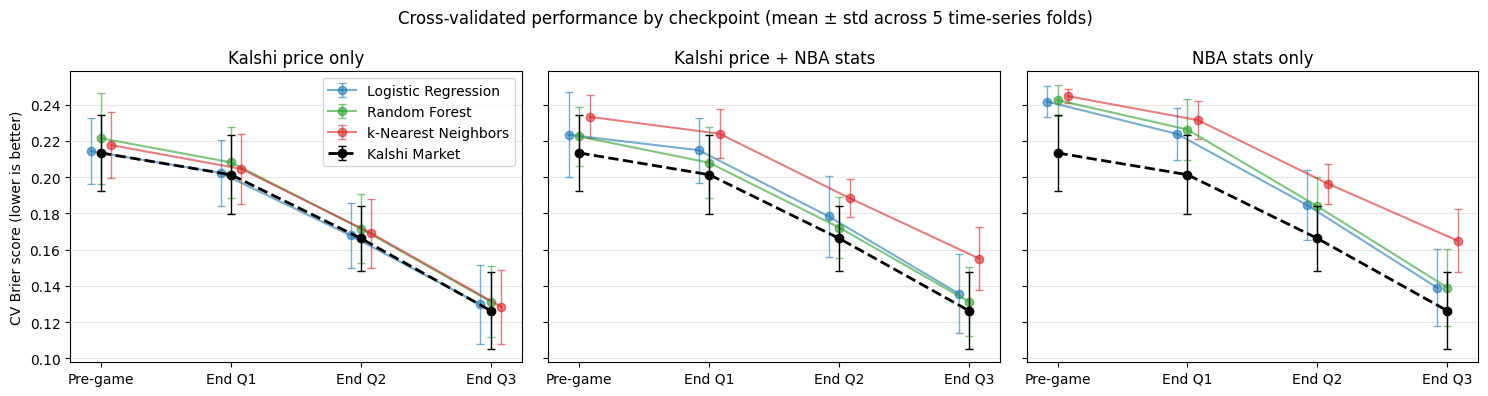

In [11]:
FEATURE_PANELS = [("kalshi_only", "Kalshi price only"),
                  ("combined", "Kalshi price + NBA stats"),
                  ("nba_stats_only", "NBA stats only")]
MODEL_STYLES = [("logistic_regression", "Logistic Regression", "tab:blue"),
                ("random_forest", "Random Forest", "tab:green"),
                ("knn", "k-Nearest Neighbors", "tab:red")]

cv_mean = metric_table("cv_brier_mean")
cv_std = metric_table("cv_brier_std")
x = np.arange(len(CHECKPOINTS))
market = ("kalshi_market", "baseline")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (feature_set_name, title) in zip(axes, FEATURE_PANELS):
    for i, (model_name, label, color) in enumerate(MODEL_STYLES):
        offset = (i - 1) * 0.08  # nudge lines sideways so error bars don't sit on top of each other
        ax.errorbar(x + offset, cv_mean.loc[(feature_set_name, model_name)],
                    yerr=cv_std.loc[(feature_set_name, model_name)],
                    marker="o", capsize=3, color=color, label=label, elinewidth=1, alpha=0.6)
    ax.errorbar(x, cv_mean.loc[market], yerr=cv_std.loc[market], color="black", linestyle="--",
                linewidth=2, marker="o", capsize=3, elinewidth=1, zorder=5, label="Kalshi Market")
    ax.set_xticks(x)
    ax.set_xticklabels(LABELS)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("CV Brier score (lower is better)")
axes[0].legend(loc="upper right", fontsize=10)
fig.suptitle("Cross-validated performance by checkpoint (mean ± std across 5 time-series folds)")
plt.tight_layout()
plt.savefig(VIZ_DIR / "04_supervised_cv_performance.png", dpi=300, bbox_inches="tight")
plt.show()

**Cross-validated performance, chart:** Each panel shows one feature set, with a line for each model family and the Kalshi market as the dashed black line. The error bars show ± one standard deviation across the 5 folds. With the Kalshi price alone, all three models land almost right on top of the market. Adding NBA stats pushes every model above the market at every checkpoint, and kNN falls furthest behind. NBA stats alone start well behind the market before the game but close much of the gap by the end of Q3 as in-game information builds up. No line drops below the market anywhere, which matches the test-set results. The error bars overlap a lot because the harder stretches of the season are hard for every approach, so Section 5’s game-by-game comparison is the better test of which differences are real.

## 5. Are the Differences Significant?

Many of the Brier score gaps above are small (0.001 to 0.005), and the test set has only 287 games, so some differences could be due to chance. A paired bootstrap estimates how much each gap would vary across different samples of games.

The test games are resampled with replacement 2,000 times. For each resample, the Brier score difference between two approaches is recomputed on the same set of games. Because both approaches are always scored on the same resampled games, the test is *paired*: it compares them game by game rather than as two independent averages, which makes it more sensitive. The middle 95% of the 2,000 differences forms a confidence interval. If the interval excludes zero, the difference is considered significant.

**Bootstrap helper:** For each game, computes the squared error of approach A minus that of approach B (the per-game Brier difference). It then averages that difference over each of the 2,000 resamples. The same resampled game indices are reused for every comparison at a checkpoint, so all comparisons are made on identical samples.

In [12]:
N_BOOT = 2000  # number of resamples
rng = np.random.default_rng(RANDOM_STATE)  # resamples are identical on every run
n_test = len(test_outcomes["pregame"])  # same 287 test games at every checkpoint
BOOT_IDX = rng.integers(0, n_test, size=(N_BOOT, n_test))  # each row = one resample of test-game positions

def paired_bootstrap(prob_a, prob_b, y):
    """Brier(A) - Brier(B) with a 95% bootstrap CI. Negative = A is better."""
    diff = (prob_a - y) ** 2 - (prob_b - y) ** 2  # per-game difference in squared error
    boot = diff[BOOT_IDX].mean(axis=1)            # mean difference within each resample
    low, high = np.percentile(boot, [2.5, 97.5])
    if high < 0:
        verdict = "better"
    elif low > 0:
        verdict = "worse"
    else:
        verdict = "n.s."
    return {"brier_diff": diff.mean(), "ci_low": low, "ci_high": high, "verdict": verdict}

def summarize(rows):
    """Turn bootstrap rows into a readable table: 'difference [CI]  verdict'."""
    df = pd.DataFrame(rows)
    df["result"] = df.apply(
        lambda r: f"{r.brier_diff:+.4f} [{r.ci_low:+.4f}, {r.ci_high:+.4f}]  {r.verdict}", axis=1)
    return df.pivot(index=["features", "model"], columns="checkpoint", values="result")[CHECKPOINTS]

### 5.1 Each Model vs. the Kalshi Market

A is the model and B is the market price. A negative difference means the model has a lower Brier score than the market. “worse” means the market is significantly better, and “n.s.” means the difference is not significant.

In [13]:
rows = []
for checkpoint in CHECKPOINTS:
    y = test_outcomes[checkpoint]
    market = test_probs[(checkpoint, "kalshi_market", "baseline")]
    for (cp, features, model), prob in test_probs.items():
        if cp == checkpoint and features != "kalshi_market":
            rows.append({"checkpoint": checkpoint, "features": features, "model": model,
                         **paired_bootstrap(prob, market, y)})

summarize(rows)

checkpoint                                                    pregame  \
features       model                                                    
combined       knn                  +0.0362 [+0.0223, +0.0505]  worse   
               logistic_regression   +0.0031 [-0.0014, +0.0081]  n.s.   
               random_forest        +0.0157 [+0.0082, +0.0229]  worse   
kalshi_only    knn                  +0.0073 [+0.0029, +0.0116]  worse   
               logistic_regression  +0.0050 [+0.0024, +0.0072]  worse   
               random_forest        +0.0117 [+0.0069, +0.0163]  worse   
naive          baseline             +0.0956 [+0.0741, +0.1159]  worse   
nba_stats_only knn                  +0.0710 [+0.0521, +0.0891]  worse   
               logistic_regression  +0.0550 [+0.0385, +0.0715]  worse   
               random_forest        +0.0565 [+0.0388, +0.0735]  worse   

checkpoint                                                      endq1  \
features       model                                                    
combined       knn                  +0.0641 [+0.0478, +0.0798]  worse   
               logistic_regression  +0.0158 [+0.0071, +0.0242]  worse   
               random_forest        +0.0111 [+0.0034, +0.0187]  worse   
kalshi_only    knn                  +0.0094 [+0.0044, +0.0143]  worse   
               logistic_regression  +0.0052 [+0.0024, +0.0076]  worse   
               random_forest        +0.0078 [+0.0014, +0.0141]  worse   
naive          baseline             +0.1137 [+0.0924, +0.1336]  worse   
nba_stats_only knn                  +0.0738 [+0.0564, +0.0898]  worse   
               logistic_regression  +0.0362 [+0.0227, +0.0502]  worse   
               random_forest        +0.0421 [+0.0257, +0.0586]  worse   

checkpoint                                                      endq2  \
features       model                                                    
combined       knn                  +0.0341 [+0.0215, +0.0465]  worse   
               logistic_regression  +0.0077 [+0.0003, +0.0149]  worse   
               random_forest        +0.0107 [+0.0055, +0.0159]  worse   
kalshi_only    knn                  +0.0032 [+0.0004, +0.0060]  worse   
               logistic_regression  +0.0023 [+0.0002, +0.0044]  worse   
               random_forest        +0.0068 [+0.0010, +0.0129]  worse   
naive          baseline             +0.1376 [+0.1162, +0.1569]  worse   
nba_stats_only knn                  +0.0468 [+0.0333, +0.0591]  worse   
               logistic_regression  +0.0207 [+0.0084, +0.0328]  worse   
               random_forest        +0.0279 [+0.0146, +0.0406]  worse   

checkpoint                                                      endq3  
features       model                                                   
combined       knn                  +0.0279 [+0.0163, +0.0396]  worse  
               logistic_regression  +0.0098 [+0.0022, +0.0186]  worse  
               random_forest        +0.0051 [+0.0005, +0.0098]  worse  
kalshi_only    knn                  +0.0074 [+0.0018, +0.0135]  worse  
               logistic_regression   -0.0009 [-0.0036, +0.0018]  n.s.  
               random_forest         +0.0026 [-0.0026, +0.0080]  n.s.  
naive          baseline             +0.1668 [+0.1483, +0.1836]  worse  
nba_stats_only knn                  +0.0408 [+0.0268, +0.0544]  worse  
               logistic_regression  +0.0200 [+0.0096, +0.0319]  worse  
               random_forest        +0.0194 [+0.0103, +0.0292]  worse

### 5.2 Combined vs. Kalshi-Only

This tests the central question directly: given the Kalshi price, do NBA stats add predictive value? For each model type, A is the model trained on combined features and B is the same model type trained on the Kalshi price alone. A negative difference means adding NBA stats helped (n.s. = not significant).

In [14]:
rows = []
for checkpoint in CHECKPOINTS:
    y = test_outcomes[checkpoint]
    for model in MODELS:
        combined = test_probs[(checkpoint, "combined", model)]
        kalshi_only = test_probs[(checkpoint, "kalshi_only", model)]
        rows.append({"checkpoint": checkpoint, "features": "combined vs kalshi_only", "model": model,
                     **paired_bootstrap(combined, kalshi_only, y)})

summarize(rows)

checkpoint                                                             pregame  \
features                model                                                    
combined vs kalshi_only knn                  +0.0289 [+0.0149, +0.0424]  worse   
                        logistic_regression   -0.0019 [-0.0060, +0.0024]  n.s.   
                        random_forest         +0.0040 [-0.0012, +0.0097]  n.s.   

checkpoint                                                               endq1  \
features                model                                                    
combined vs kalshi_only knn                  +0.0548 [+0.0395, +0.0698]  worse   
                        logistic_regression  +0.0106 [+0.0031, +0.0181]  worse   
                        random_forest         +0.0033 [-0.0033, +0.0098]  n.s.   

checkpoint                                                               endq2  \
features                model                                                    
combined vs kalshi_only knn                  +0.0308 [+0.0182, +0.0437]  worse   
                        logistic_regression   +0.0054 [-0.0024, +0.0129]  n.s.   
                        random_forest         +0.0039 [-0.0024, +0.0104]  n.s.   

checkpoint                                                               endq3  
features                model                                                   
combined vs kalshi_only knn                  +0.0204 [+0.0074, +0.0334]  worse  
                        logistic_regression  +0.0107 [+0.0029, +0.0197]  worse  
                        random_forest         +0.0025 [-0.0033, +0.0083]  n.s.

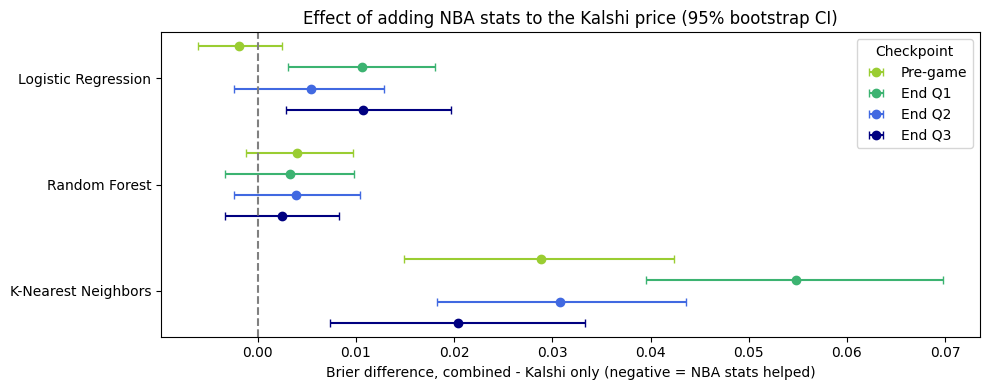

In [15]:
# Figure: Brier difference from adding NBA stats to the Kalshi price, with 95% bootstrap CIs

comparison = pd.DataFrame(rows)  # section 5.2 results

model_labels = {"logistic_regression": "Logistic Regression",
                "random_forest": "Random Forest",
                "knn": "K-Nearest Neighbors"}

colors = ["yellowgreen", "mediumseagreen", "royalblue", "navy"]

fig, ax = plt.subplots(figsize=(10, 4))

y, y_ticks, y_tick_labels = 0, [], []  # y = vertical position of the next dot
for model in MODELS:
    for checkpoint, label, color in zip(CHECKPOINTS, LABELS, colors):
        row = comparison[(comparison["model"] == model) & (comparison["checkpoint"] == checkpoint)].iloc[0]
        error = [[row["brier_diff"] - row["ci_low"]], [row["ci_high"] - row["brier_diff"]]]  # whisker lengths
        ax.errorbar(row["brier_diff"], y, xerr=error, fmt="o", color=color, capsize=3, 
                    label=label if model == "logistic_regression" else None)  
        y += 1
    y_ticks.append(y - 2.5)  # center of the model's four rows (checkpoints)
    y_tick_labels.append(model_labels[model])
    y += 1

ax.invert_yaxis()  # first model (logistic regression) and pre-game at top of chart
ax.axvline(0, color="gray", linestyle="--")
ax.set_yticks(y_ticks)
ax.set_yticklabels(y_tick_labels)
ax.set_xlabel("Brier difference, combined - Kalshi only (negative = NBA stats helped)")
ax.set_title("Effect of adding NBA stats to the Kalshi price (95% bootstrap CI)")
ax.legend(title="Checkpoint", loc="upper right")

plt.tight_layout()
plt.savefig(VIZ_DIR / "05_supervised_combined_vs_kalshi_only.png", dpi=300, bbox_inches="tight")
plt.show()

**Combined vs. Kalshi-only, chart:** Visualizes Section 5.2. Each dot is the Brier difference from adding NBA stats to the Kalshi price for one model at one checkpoint, and the whiskers show the 95% bootstrap interval. Dots left of zero mean the stats helped, and dots right of zero mean they hurt. Whiskers that cross zero mean the difference is not significant. No interval falls entirely left of zero, so adding NBA stats never significantly improved predictions. Random forest shows no significant difference at any checkpoint. Logistic regression is significantly worse at End Q1 and End Q3, and kNN is significantly worse at every checkpoint, since it weighs every feature equally and the weak ones dilute the market price.

## 6. In-Depth Evaluation

The best models overall use the Kalshi price alone, which leaves little to analyze with a single feature. This section focuses on combined logistic regression: it’s the strongest model that actually uses NBA stats, its coefficients are easy to interpret, and it directly tests the project’s question of whether the stats add anything beyond the market price.

### 6.1 Feature Effects / Importance

Coefficients from the combined logistic regression at each checkpoint, showing the 10 features with the largest effect at any checkpoint. Because features are standardized inside the pipeline, each coefficient is the change in log-odds of a home win per one standard deviation of that feature, so magnitudes are comparable across features. NaN cells are in-game features, which don't exist pregame. Several box-score stats overlap (for example `FGM`, `FGA`, `FG_PCT`, `PTS`), so small coefficients among them shouldn't be read individually.

In [16]:
# coefficients from the combined logistic regression at each checkpoint (one column per checkpoint)
coefs = {}
for checkpoint in CHECKPOINTS:
    model = fitted_models[(checkpoint, "combined", "logistic_regression")]
    coefficients = model.named_steps["logisticregression"].coef_[0]  # one coefficient per feature
    feature_names = feature_sets(tables[checkpoint])["combined"]     # same order the model was trained on
    coefs[checkpoint] = pd.Series(coefficients, index=feature_names)

coef_table = pd.concat(coefs, axis=1)  # in-game features are NaN at pre-game

# 10 features with the largest absolute coefficient at any checkpoint
top_features = coef_table.abs().max(axis=1).sort_values(ascending=False).index[:10]
coef_table.loc[top_features].round(3)

,pregame,endq1,endq2,endq3
KALSHI_PROB_HOME,0.801,0.428,0.823,0.820
IG_SCORE_DIFF,NaN,0.105,0.238,0.464
IG_FG_PCT,NaN,0.083,0.350,0.434
IG_TOV,NaN,0.015,-0.143,-0.423
IG_FGM,NaN,0.103,0.270,0.394
IG_AST,NaN,0.056,0.089,0.330
ROLL_PLUS_MINUS,0.211,0.197,0.229,0.165
IG_FG3A,NaN,0.091,0.165,0.203
IG_STL,NaN,0.027,-0.143,-0.200
IG_FG3M,NaN,0.011,-0.021,0.197


**What the coefficients show:** `KALSHI_PROB_HOME` has the largest coefficient at every checkpoint. In-game stats gain weight as the game progresses: by End Q3, the score margin, field-goal percentage, and turnovers each carry about half the weight of the market price. `ROLL_PLUS_MINUS` is the only rolling stat in the top 10, with a steady, modest effect. Because each checkpoint's model selected its own regularization strength (End Q1 chose a stronger setting, which shrinks all of its coefficients), magnitudes should be compared within a checkpoint, not across them.

Although the model gives in-game stats substantial weight by End Q3, adding them still made test-set predictions significantly worse than the Kalshi price alone (Section 5.2). The weight they earn on training games doesn't carry over, which suggests the market price already reflects the score and box-score information.

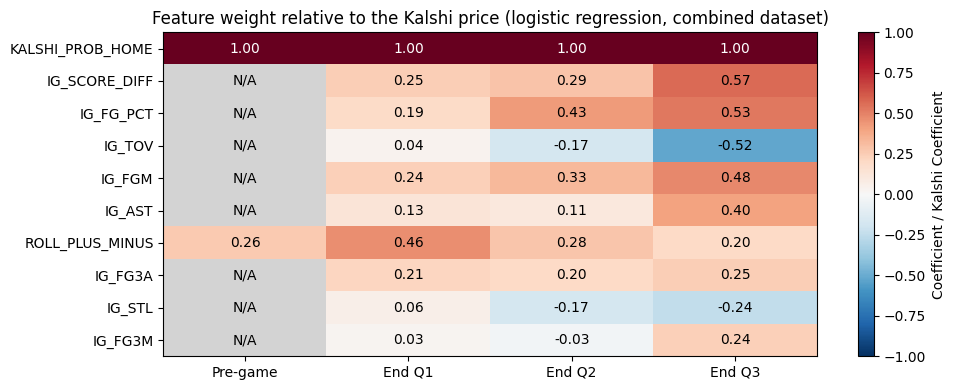

In [17]:
# Figure: each feature's logistic regression coefficient relative to the Kalshi coefficient, by checkpoint

relative = coef_table.loc[top_features].div(coef_table.loc["KALSHI_PROB_HOME"], axis=1)  # Kalshi = 1.00 in every column

cmap = plt.cm.RdBu_r.copy()  # red = favors home, blue = favors away
cmap.set_bad("lightgrey")    # color for NaN cells (in-game stats at pre-game checkpoint)

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(np.ma.masked_invalid(relative.values), cmap=cmap, vmin=-1, vmax=1, aspect="auto")

# write each value in its cell, with white text on darker cells
for i in range(relative.shape[0]):      # rows (features)
    for j in range(relative.shape[1]):  # columns (checkpoints)
        value = relative.iat[i, j]
        text = "N/A" if np.isnan(value) else f"{value:.2f}"
        color = "white" if abs(value) > 0.6 else "black"
        ax.text(j, i, text, ha="center", va="center", color=color)  # x = column, y = row

ax.set_xticks(range(len(LABELS)))
ax.set_xticklabels(LABELS)
ax.set_yticks(range(len(relative)))
ax.set_yticklabels(relative.index)
ax.set_title("Feature weight relative to the Kalshi price (logistic regression, combined dataset)")
fig.colorbar(im, ax=ax, label="Coefficient / Kalshi Coefficient")

plt.tight_layout()
plt.savefig(VIZ_DIR / "06_supervised_relative_coefficients.png", dpi=300, bbox_inches="tight")
plt.show()

**Relative feature weights, chart:** Shows each feature's coefficient from the combined logistic regression divided by the Kalshi coefficient at the same checkpoint, so every column is on the same scale (Kalshi = 1.00). Red pushes toward a home win and blue toward an away win, and grey cells are in-game stats that don't exist pre-game. In-game stats gain weight as the game goes on: by End Q3, the score margin, field-goal percentage, field goals made, and turnovers each carry about half the weight of the market price. Despite that weight, adding these stats did not improve test-set predictions (see Section 5), which suggests the market price already reflects them. Some signs, such as negative steals, come from overlap between related box-score stats and shouldn't be read individually.

### 6.2 Ablation

This checks which groups of NBA stats help or hurt when added to the Kalshi price. Each row starts from the Kalshi price alone and adds one group: the score margin, the full in-game box score, the five-game rolling stats, or everything together. Each version is a logistic regression tuned the same way as the main models, and scored with cross-validated Brier score (mean ± standard deviation across the 5 folds). The short version: the score margin barely changes anything, the in-game stats are roughly neutral by the end of Q3, and the rolling stats are what make the combined model worse.

In [18]:
rows = []
for checkpoint, table in tables.items():
    train, _ = split(table)
    rolling = [col for col in table if col.startswith("ROLL_")]
    in_game = [col for col in table if col.startswith("IG_")]
    variants = {"Kalshi only": [], "+ rolling stats": rolling, "+ all NBA stats": rolling + in_game}
    if in_game:
        variants.update({"+ score margin": ["IG_SCORE_DIFF"], "+ in-game stats": in_game})

    for variant, extra in variants.items():
        search = GridSearchCV(MODELS["logistic_regression"], PARAM_GRIDS["logistic_regression"],
                              cv=CV, scoring="neg_brier_score", n_jobs=-1)
        search.fit(train[["KALSHI_PROB_HOME"] + extra], train["HOME_WIN"])
        cv, i = search.cv_results_, search.best_index_
        rows.append({"variant": variant, "checkpoint": checkpoint,
                     "cv_brier": f"{-cv['mean_test_score'][i]:.4f} ± {cv['std_test_score'][i]:.4f}"})

order = ["Kalshi only", "+ score margin", "+ in-game stats", "+ rolling stats", "+ all NBA stats"]
pd.DataFrame(rows).pivot(index="variant", columns="checkpoint", values="cv_brier").reindex(index=order, columns=CHECKPOINTS)

checkpoint,pregame,endq1,endq2,endq3
variant,,,,
Kalshi only,0.2143 ± 0.0180,0.2023 ± 0.0183,0.1678 ± 0.0179,0.1298 ± 0.0218
+ score margin,NaN,0.2026 ± 0.0177,0.1662 ± 0.0148,0.1293 ± 0.0213
+ in-game stats,NaN,0.2096 ± 0.0214,0.1693 ± 0.0168,0.1293 ± 0.0188
+ rolling stats,0.2233 ± 0.0235,0.2114 ± 0.0244,0.1779 ± 0.0247,0.1383 ± 0.0226
+ all NBA stats,0.2233 ± 0.0235,0.2148 ± 0.0178,0.1783 ± 0.0223,0.1358 ± 0.0218


### 6.3 Sensitivity Analysis

The grid search already scored every hyperparameter setting it tried, so this table pulls out those CV Brier scores for the combined feature set to show how much each model depends on its settings. Logistic regression is the most stable: any C from 0.01 to 0.1 gives nearly the same score, and only the most heavily regularized setting clearly hurts. Random forest is much more sensitive, getting steadily worse as leaf size grows, and kNN falls in between. Even so, no setting of any model beats the Kalshi market’s Brier score at any checkpoint, so choosing different hyperparameters wouldn’t have changed the finding that NBA stats don’t add value beyond the market.

In [19]:
rows = []
for (checkpoint, features, model), search in searches.items():
    if features == "combined":
        cv = search.cv_results_
        for params, brier in zip(cv["params"], cv["mean_test_brier"]):
            setting = ", ".join(f"{name.split('__')[-1]}={value}" for name, value in params.items())
            rows.append({"model": model, "setting": setting, "checkpoint": checkpoint, "cv_brier": round(-brier, 4)})

pd.DataFrame(rows).pivot(index=["model", "setting"], columns="checkpoint", values="cv_brier")[CHECKPOINTS]

checkpoint                                                   pregame   endq1  \
model               setting                                                    
knn                 n_neighbors=100, weights=distance         0.2363  0.2269   
                    n_neighbors=100, weights=uniform          0.2370  0.2277   
                    n_neighbors=25, weights=distance          0.2338  0.2239   
                    n_neighbors=25, weights=uniform           0.2332  0.2243   
                    n_neighbors=50, weights=distance          0.2338  0.2242   
                    n_neighbors=50, weights=uniform           0.2340  0.2249   
                    n_neighbors=75, weights=distance          0.2349  0.2264   
                    n_neighbors=75, weights=uniform           0.2353  0.2272   
logistic_regression C=0.001                                   0.2407  0.2300   
                    C=0.01                                    0.2254  0.2148   
                    C=0.1                                     0.2233  0.2163   
                    C=1                                       0.2275  0.2237   
random_forest       max_features=0.5, min_samples_leaf=100    0.2289  0.2229   
                    max_features=0.5, min_samples_leaf=25     0.2224  0.2079   
                    max_features=0.5, min_samples_leaf=50     0.2256  0.2159   
                    max_features=sqrt, min_samples_leaf=100   0.2383  0.2332   
                    max_features=sqrt, min_samples_leaf=25    0.2272  0.2156   
                    max_features=sqrt, min_samples_leaf=50    0.2327  0.2254   

checkpoint                                                    endq2   endq3  
model               setting                                                  
knn                 n_neighbors=100, weights=distance        0.1958  0.1683  
                    n_neighbors=100, weights=uniform         0.1970  0.1706  
                    n_neighbors=25, weights=distance         0.1884  0.1550  
                    n_neighbors=25, weights=uniform          0.1884  0.1557  
                    n_neighbors=50, weights=distance         0.1901  0.1562  
                    n_neighbors=50, weights=uniform          0.1906  0.1570  
                    n_neighbors=75, weights=distance         0.1925  0.1603  
                    n_neighbors=75, weights=uniform          0.1933  0.1615  
logistic_regression C=0.001                                  0.2080  0.1878  
                    C=0.01                                   0.1785  0.1411  
                    C=0.1                                    0.1783  0.1358  
                    C=1                                      0.1867  0.1427  
random_forest       max_features=0.5, min_samples_leaf=100   0.2011  0.1784  
                    max_features=0.5, min_samples_leaf=25    0.1722  0.1313  
                    max_features=0.5, min_samples_leaf=50    0.1848  0.1564  
                    max_features=sqrt, min_samples_leaf=100  0.2135  0.1937  
                    max_features=sqrt, min_samples_leaf=25   0.1788  0.1407  
                    max_features=sqrt, min_samples_leaf=50   0.1949  0.1670

## 7. Failure Analysis

This section looks at specific test games where the combined logistic regression got it badly wrong at the end of Q3, when the models are most confident. It checks three kinds of failure and shows the top three candidates for each:

1. **Random error:** the market itself was confidently wrong, an upset no model could see coming.
2. **Noisy features:** a close game where the market was right but the NBA stats pulled the model the wrong way.
3. **Missing information:** a game with a big margin where the market was still right and the model wasn't, suggesting the market knew something the box score didn't.

The biggest failure in each category is analyzed below.

In [20]:
cp = "endq3"
_, test = split(tables[cp])
games = test[["GAME_ID", "IG_SCORE_DIFF", "KALSHI_PROB_HOME", "HOME_WIN"]].copy()
games["p_combined"] = test_probs[(cp, "combined", "logistic_regression")].round(3)
market_err = (games["KALSHI_PROB_HOME"] - games["HOME_WIN"]) ** 2
extra_err = (games["p_combined"] - games["HOME_WIN"]) ** 2 - market_err  # how much worse the model did than the market
margin = games["IG_SCORE_DIFF"].abs()

candidates = {"1. Random error: market most confidently wrong": market_err,
              "2. Noisy features: close game, NBA stats pulled the model the wrong way": extra_err[margin <= 2],
              "3. Missing information: big margin, market still right and the model wasn't": extra_err[margin >= 5]}
chosen = []
for title, error in candidates.items():
    top = error.sort_values(ascending=False).index[:3]
    print(title)
    display(games.loc[top])
    chosen.append(games.loc[top[0], "GAME_ID"])  # biggest failure in each category

1. Random error: market most confidently wrong


,GAME_ID,IG_SCORE_DIFF,KALSHI_PROB_HOME,HOME_WIN,p_combined
854,22500916,11.0,0.975000,0,0.950
1118,22501184,-7.0,0.084577,1,0.132
894,22500958,12.0,0.895000,0,0.952


2. Noisy features: close game, NBA stats pulled the model the wrong way


,GAME_ID,IG_SCORE_DIFF,KALSHI_PROB_HOME,HOME_WIN,p_combined
1038,22501099,0.0,0.565000,1,0.242
1012,22501066,2.0,0.325000,0,0.595
855,22500918,1.0,0.328283,0,0.565


3. Missing information: big margin, market still right and the model wasn't


,GAME_ID,IG_SCORE_DIFF,KALSHI_PROB_HOME,HOME_WIN,p_combined
957,22501021,-9.0,0.484848,1,0.218
1014,22501072,-7.0,0.661692,1,0.345
952,22501013,-6.0,0.512563,1,0.343


**End-of-game info:** Pulls team names, dates, and final scores from the full-game box scores so each failure can be matched to what actually happened. Neutral-site games (with no home team) are dropped.

In [21]:
box = pd.read_csv("../data/raw/_team-box-stats(full-game).csv", dtype={"GAME_ID": int})
home = box[box["MATCHUP"].str.contains("vs.")].drop_duplicates("GAME_ID").set_index("GAME_ID")
away = box[box["MATCHUP"].str.contains("@")].drop_duplicates("GAME_ID").set_index("GAME_ID")
game_info = pd.DataFrame({"date": home["GAME_DATE"], "home": home["TEAM_NAME"], "away": away["TEAM_NAME"],
                        "final": home["PTS"].astype(str) + " - " + away["PTS"].astype(str)}).dropna()

**Failure table:** One row per chosen game. The **effect** columns show how much each feature group pushed the model's prediction toward a home win (positive) or an away win (negative), measured in log-odds. For a linear model like logistic regression, this is exactly what SHAP values measure. `home_margin_q3` is the home team's lead after three quarters, and `market_prob` and `model_prob` are each one's predicted chance of a home win at that point.

In [22]:
cols = feature_sets(tables[cp])["combined"]
model = fitted_models[(cp, "combined", "logistic_regression")]
z = model.named_steps["standardscaler"].transform(test[cols])
contribution = pd.DataFrame(z * model.named_steps["logisticregression"].coef_[0], columns=cols, index=test["GAME_ID"])
groups = ["Kalshi" if c.startswith("KALSHI") else c.split("_")[0] for c in cols]  # Kalshi / ROLL / IG
effects = contribution.loc[chosen].T.groupby(groups).sum().T.round(2)  # positive = effect toward a home win (log-odds)

failures = games.set_index("GAME_ID").loc[chosen].join(game_info).join(effects)
failures.insert(0, "reason", ["Random error (upset)", "Noisy features", "Missing information"])
failures["HOME_WIN"] = failures["HOME_WIN"].astype(bool)
failures = failures.rename(columns={"IG_SCORE_DIFF": "home_margin_q3", "HOME_WIN": "home_win", "KALSHI_PROB_HOME": "market_prob", "p_combined": "model_prob",
                         "IG": "in_game_effect", "Kalshi": "kalshi_effect", "ROLL": "rolling_effect"}).round(3)
failures = failures[["reason", "date", "home", "away", "home_win","final", "home_margin_q3", "market_prob", "model_prob", "in_game_effect", "kalshi_effect", "rolling_effect"]]

display(failures)

,reason,date,home,away,home_win,final,home_margin_q3,market_prob,model_prob,in_game_effect,kalshi_effect,rolling_effect
GAME_ID,,,,,,,,,,,,
22500916,Random error (upset),2026-03-07,Detroit Pistons,Brooklyn Nets,False,105 - 107,11.0,0.975,0.950,1.38,1.04,0.27
22501099,Noisy features,2026-03-31,Orlando Magic,Phoenix Suns,True,115 - 111,0.0,0.565,0.242,-0.86,0.08,-0.63
22501021,Missing information,2026-03-20,Denver Nuggets,Toronto Raptors,True,121 - 115,-9.0,0.485,0.218,-1.16,-0.10,-0.28


**What the failures show:**
- **Brooklyn @ Detroit (random error):** Detroit led by 11 after Q3 with a 97.5% market price, and every feature group agreed. Brooklyn won the fourth by 13 and the game 107–105. Nothing at the end of Q3 pointed to that collapse, so this is noise no model can predict.
- **Phoenix @ Orlando (noisy features):** In a tied game, the market's 56.5% for Orlando was right, but a near-even price barely moves the model, so the NBA stats decided it and pulled it down to 24%. This matches the ablation, and dropping the rolling stats or regularizing the NBA features more would help.
- **Toronto @ Denver (missing information):** Down 9 after Q3, Denver still had a 48.5% market price, so the market saw something the box score didn't. The model counted the deficit twice, once inside the price and once on its own, and dropped to 22% before Denver won 121–115. Modeling what the stats add *beyond* the market, or adding team-strength and injury features, would address this.

## 8. Summary of Findings

**Question:** Do traditional NBA statistics add predictive value beyond Kalshi prediction-market prices, and does that change as a game progresses?

**Short answer:** No. Across all four checkpoints, no model beat the Kalshi market price, either in cross-validation on the training games or on the held-out test games. Adding NBA statistics to the market price never significantly improved predictions, and in several cases it made them significantly worse.

### Brier scores (lower is better)

| Checkpoint | Market (test) | Best Kalshi-only (test) | Best combined (test) | Best NBA-only (test) | Naive (test) | Market (CV) | Best model (CV) |
|---|---|---|---|---|---|---|---|
| Pre-game | **0.1482** | 0.1532 | 0.1513 | 0.2032 | 0.2438 | **0.2133 ± 0.0207** | 0.2143 ± 0.0180 |
| End Q1 | **0.1301** | 0.1353 | 0.1412 | 0.1663 | 0.2438 | **0.2013 ± 0.0217** | 0.2023 ± 0.0183 |
| End Q2 | **0.1062** | 0.1085 | 0.1139 | 0.1269 | 0.2438 | **0.1662 ± 0.0179** | 0.1678 ± 0.0179 |
| End Q3 | 0.0771 | **0.0761** | 0.0822 | 0.0965 | 0.2438 | **0.1263 ± 0.0211** | 0.1285 ± 0.0205 |

The best CV model is Kalshi-only logistic regression through End Q2 and Kalshi-only kNN at End Q3.

### Key findings

1. **The Kalshi market was the strongest predictor at every checkpoint.** On the test games, no model was significantly better than the raw market price; only three model-checkpoint combinations matched it statistically (combined logistic regression pre-game, and Kalshi-only logistic regression and random forest at End Q3). The one model with a lower test Brier score than the market (Kalshi-only logistic regression at End Q3, 0.0761 vs. 0.0771) was within bootstrap noise. Cross-validation on the training games reached the same conclusion: no model family or feature set beat the market at any checkpoint.

2. **NBA statistics added no measurable value beyond the market, and the rolling stats are the main reason.** Comparing each model type trained on combined features with the same model on the Kalshi price alone, the combined version was never significantly better (0 of 12 comparisons) and was significantly worse in 6 of 12. The ablation shows where the damage comes from: adding just the score margin to the market price barely changes the CV Brier score, the full in-game box score is roughly neutral by End Q3, and the five-game rolling stats make predictions about 0.009–0.010 worse at every checkpoint. This is consistent with the market already pricing in the score and recent team form, leaving the extra stats mostly as noise for the model to fit.

3. **NBA statistics carry real signal on their own.** NBA-only models beat the naive baseline by a wide margin at every checkpoint, and their gap to the market narrowed from about 0.055 pre-game to about 0.02 by End Q2 and Q3 as the score margin became the dominant signal. Pre-game, rolling averages captured far less than the market, which can also reflect injuries, rest, and matchups.

4. **Logistic regression was the most reliable model.** It was the best or near-best model for nearly every feature set and checkpoint, and the sensitivity analysis showed it is also the most stable: any C from 0.01 to 0.1 gives nearly the same CV Brier score. Random forest was slightly ahead in a few test-set cases (combined at End Q1 and End Q3, NBA-only at End Q3) but is far more sensitive to its settings, with its End Q3 CV Brier ranging from 0.131 to 0.194 across leaf sizes. kNN was the weakest model whenever NBA stats were included, because it weighs every standardized feature equally, so the many weak rolling stats dilute the strong signals. With the Kalshi price alone, however, kNN was competitive and even had the best CV score at End Q3. No hyperparameter setting of any model reached the market's CV Brier score, so different tuning choices wouldn't change the main conclusion.

5. **Recalibrating the market price did not help.** Kalshi-only models, which learn a mapping from market price to outcome, were significantly worse than the raw price on the test games from pre-game through End Q2, and only logistic regression and random forest matched it at End Q3. Any adjustment learned during the training period didn't transfer, suggesting the market's prices were already well calibrated.

6. **Failures fall into three distinct categories.** Some are pure upsets the market and every model got wrong (Brooklyn erasing an 11-point fourth-quarter deficit at Detroit). Some come from noisy features: in a tied game, a near-even market price barely moves the model, so the NBA stats decide the prediction and can pull it the wrong way. The most revealing is missing information: when Denver trailed by 9 but the market still gave them 48.5%, the model counted the deficit twice (once inside the price and once on its own) and dropped to 22% before Denver won. This double-counting is a likely reason combining the price with box-score stats doesn't help.

### Limitations

- **One season, 287 test games.** Results reflect a single NBA season, and the test set is small enough that differences below about 0.003 in Brier score are generally not distinguishable from chance.
- **Late-season test period.** The chronological split places the test set in March and April, when the home win rate (61.3%) was well above the training period's (53.2%) and lopsided matchups were more common. The market's Brier score was 31–39% lower on the test games than across the training folds at every checkpoint, so the test games were unusually easy and raised the bar for every model. This is also why test-set scores look much better than CV scores throughout.
- **Grid edges.** With NBA stats included, random forest and kNN usually chose the smallest leaf size and neighbor count in their grids, so slightly smaller values might help them a little. The sensitivity analysis suggests this wouldn't close the gap to the market.
- **Multiple comparisons.** About 50 significance tests were run, so a few individual "significant" results could occur by chance. The overall conclusion rests on the consistent direction of the results across models, checkpoints, and both evaluation methods rather than on any single comparison.
- **Independence assumption.** The bootstrap treats games as independent, although games involving the same team on nearby dates are somewhat related.